В цьому домашньому завданні ми з вами побудуємо повноцінне ML-рішення реальної ML-задачі. Ви вже маєте всі знання, які для цього потрібні. Дотримуйтесь інструкцій, та користуйтесь матеріалами лекцій, аби виконувати завдання. Тут інструкції будуть детальні, а в подільших завданнях - будуть ставати все менш детальними, аби ви вже починали самостійно структурувати ML-проєкт і до кінця курсу для вас розвʼязати будь-яку ML–задачу було eazy-breezy.

## Dataset

Будемо працювати з набором даних `cars.csv`, який описує автомобілі і їх ціну у індійських рупіях :) Мета - передбачити ціну авто за його характеристиками. Опис набору даних:

| Назва рядка            | Опис                                                                                                                                                 |
|------------------------|--------------------------------------------------------------------------------------------------------------------------------------------------------|
| Car_ID                 | Унікальний ідентифікатор для кожного оголошення про автомобіль.                                                                                         |
| Brand                  | Бренд або виробник автомобіля (наприклад, Toyota, Honda, Ford тощо).                                                                                     |
| Model                  | Модель автомобіля (наприклад, Camry, Civic, Mustang тощо).                                                                                               |
| Year                   | Рік виготовлення автомобіля.                                                                                                                            |
| Kilometers_Driven      | Загальний пробіг автомобіля у кілометрах.                                                                                                               |
| Fuel_Type              | Тип палива, який використовує автомобіль (наприклад, бензин, дизель, електро тощо).                                                                      |
| Transmission           | Тип трансмісії автомобіля (наприклад, механічна, автоматична).                                                                                           |
| Owner_Type             | Кількість попередніх власників автомобіля (наприклад, перший, другий, третій).                                                                           |
| Mileage                | Паливна ефективність автомобіля у кілометрах на літр.                                                                                                   |
| Engine                 | Об'єм двигуна автомобіля в кубічних сантиметрах (CC).                                                                                                   |
| Power                  | Максимальна потужність автомобіля в кінських силах (bhp).                                                                                               |
| Seats                  | Кількість місць в автомобілі.                                                                                                                           |
| Price                  | Вартість автомобіля в INR (індійські рупії), що є цільовою змінною для прогнозування.                                                                   |

# Імпорти

Для зручності рекомендую всі імпорти розмістити тут нагорі, аби коли ви перезавантажували ноутбук, одразу можна було в один запуск клітинки імпортувати всі потрібні бібліотеки.

In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import OrdinalEncoder
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import StandardScaler
import statsmodels.api as sm

# Знайомство з даними

**Завдання 1.** Завантажте набір даних `cars.csv` в pandas.DataFrame. Виведіть перші 5 записів.

In [2]:
df = pd.read_csv("cars.csv")
df.head()

,Car_ID,Brand,Model,Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Mileage,Engine,Power,Seats,Price
0,1,Toyota,Corolla,2018,50000,Petrol,Manual,First,15,1498,108,5,800000
1,2,Honda,Civic,2019,40000,Petrol,Automatic,Second,17,1597,140,5,1000000
2,3,Ford,Mustang,2017,20000,Petrol,Automatic,First,10,4951,395,4,2500000
3,4,Maruti,Swift,2020,30000,Diesel,Manual,Third,23,1248,74,5,600000
4,5,Hyundai,Sonata,2016,60000,Diesel,Automatic,Second,18,1999,194,5,850000


**Завдання 2.** Виведіть типи даних колонок даних, а також дослідіть, які по факту типи даних мають записи в кожній колонці (тип `object` може містити різні типи даних) і скільки значень є в кожній категоріальній колонці.

Напишіть висновок, скільки в наборі даних числових та категоріальних колонок кожного з трьох різних типів (бінарна, мільтикатегоріальна без порядку, мультикатегоріальна з порядком). Шаблон висновку

```
В наборі даних 10 числових і 10 категоріальних колонок з них
- 2 бінарні (мають лише 2 значення)
- 6 мультикатегоріальних (більше 2х значень) зі значеннями, для яких немає відношення порядку
- 2 колонки, в яких можна встановити відношення порядку (наприклад Small<Medium<Large)
```

Якщо не знаєте, як це зробити з `pandas` - ось підказка, які методи можуть допомогти вам виконати це завдання

- pandas.DataFrame.info()
- pandas.DataFrame.dtypes
- pandas.DataFrame.loc[...]
- pandas.DataFrame.select_dtypes(...)
- pandas.Series.unique()
- pandas.Series.nunique()

Детальніше ознайомитись з кожним ви можете в [документації](https://pandas.pydata.org/docs/reference/frame.html), або написати в окремій клітинці знак питання і назву методу (тільки приберіть це перед здачею, бо перегляд документації - не допомагає зрозуміти дані і хід думок, а Ваша робота - це як презентація замовнику зробленої задачі).


In [3]:
df.info()

print("\nТипи даних:")
print(df.dtypes)

print("\nФактичні типи значень:")
for col in df.columns:
    print(f"{col}: {df[col].dropna().map(type).value_counts().to_dict()}")

cat_cols = df.select_dtypes(include=["object", "category"]).columns

for col in cat_cols:
    print(f"\n{col}: {df[col].nunique()} унікальних значень")
    print(df[col].value_counts(dropna=False))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Car_ID             100 non-null    int64 
 1   Brand              100 non-null    object
 2   Model              100 non-null    object
 3   Year               100 non-null    int64 
 4   Kilometers_Driven  100 non-null    int64 
 5   Fuel_Type          100 non-null    object
 6   Transmission       100 non-null    object
 7   Owner_Type         100 non-null    object
 8   Mileage            100 non-null    int64 
 9   Engine             100 non-null    int64 
 10  Power              100 non-null    int64 
 11  Seats              100 non-null    int64 
 12  Price              100 non-null    int64 
dtypes: int64(8), object(5)
memory usage: 10.3+ KB

Типи даних:
Car_ID                int64
Brand                object
Model                object
Year                  int64
Kilometers_Driv

Висновок: у наборі даних 13 колонок: 7 числових, 5 категоріальних та 1 ідентифікатор (`Car_ID`).

Серед 5 категоріальних колонок:
- **2 бінарні** — `Fuel_Type` (Petrol, Diesel) та `Transmission` (Automatic, Manual).
- **2 мультикатегоріальні без порядку** — `Brand` (11 значень) та `Model` (58 значень).
- **1 мультикатегоріальна з порядком** — `Owner_Type` (First, Second, Third), оскільки можна встановити порядок між категоріями.

Усі 100 записів заповнені, пропущених значень немає. Фактичні типи значень відповідають типам даних колонок.

**Завдання 3**. Розділіть дані на тренувальні і тест. Відведіть в тест 20%, поставте `random_state=12`. Ми будемо передбачати колонку `Price` - тож, вона є цільовою змінною. В результаті у Вас має бути 4 набори даних `X_train, X_test, y_train, y_test`.

Надалі ми всюди тренуємо методи для кодування, масштабування та саму модель тільки на тренувальних даних X_train (та y_train для моделі), а на тестувальних лише використовуємо вже навчені методи для кодування, масштабування і модель викликаючи в них `transform()` (для методів обробки даних) або `predict()` (для моделі).

І так само треба робити завжди.

In [6]:
X = df.drop(columns=["Price", "Car_ID"])
y = df["Price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=12
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (80, 11)
X_test: (20, 11)
y_train: (80,)
y_test: (20,)


**Завдання 4**. Кодуємо категоріальні колонки.

1. Закодуйте колонки з бінарними значеннями `Fuel_Type` і `Transmission` так, аби вони були у чисельному представленні і містили лише 0 так 1. Приклад був у лекції. Значення 1 нехай буде у категорії, яка містить більше значень в колонці.

2. Закодуйте колонку `Brand` з використанням `sklearn.preprocessing.OneHotEncoder` аналогічно до того, як ми робили це в лекції. Увага! Ми робимо виклик методу `Encoder.fit()` на тренувальних даних `X_train`, а на тестувальних тільки викликаємо `Encoder.transform()`. Додайте закодовані значення в набори даних `X_train`, `X_test`.

3. Колонку `Owner_Type` з використанням `sklearn.preprocessing.OrdinalEncoder` я закодую для вас. Проаналізуйте, що відбувається.

Колонка `Model` містять забагато значень для кодування в тому вигляді, як вона є зараз, з огляду на невелику кількість даних. Якщо ви бачите, як можна згрупувати значення в цій колонці скоротивши кількість унікальних значень до 3-5, то можете виконати ще цю трансформацію, використати цю колонку в моделі і отримати додаткову практику і бал, якщо все буде зроблено правильно. А якщо неправильно - то фідбек на Вашу роботу :)

In [7]:
X_train["Fuel_Type_Code"] = X_train["Fuel_Type"].map({
    "Petrol": 1, "Diesel": 0
})
X_test["Fuel_Type_Code"] = X_test["Fuel_Type"].map({
    "Petrol": 1, "Diesel": 0
})

X_train["Transmission_Code"] = X_train["Transmission"].map({
    "Automatic": 1, "Manual": 0
})
X_test["Transmission_Code"] = X_test["Transmission"].map({
    "Automatic": 1, "Manual": 0
})

In [9]:
ohe = OneHotEncoder(
    sparse_output=False,
    handle_unknown="ignore"
)

ohe.fit(X_train[["Brand"]])

train_encoded = ohe.transform(X_train[["Brand"]])
test_encoded = ohe.transform(X_test[["Brand"]])

brand_cols = ohe.get_feature_names_out(["Brand"])

X_train[brand_cols] = train_encoded
X_test[brand_cols] = test_encoded

In [11]:
ordenc = OrdinalEncoder(categories=[['First', 'Second', 'Third']]) # визначаємо порядок категорій
ordenc.fit(X_train[['Owner_Type']])

X_train['Owner_Type_Codes'] = ordenc.transform(X_train[['Owner_Type']])
X_test['Owner_Type_Codes'] = ordenc.transform(X_test[['Owner_Type']])

Очікуваний результат після трансформацій:

In [14]:
pd.set_option('display.max_columns', 100)
display(X_train.head()), display(X_test.head())

,Brand,Model,Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Mileage,Engine,Power,Seats,Fuel_Type_Code,Transmission_Code,Brand_Audi,Brand_BMW,Brand_Ford,Brand_Honda,Brand_Hyundai,Brand_Mahindra,Brand_Maruti,Brand_Mercedes,Brand_Tata,Brand_Toyota,Brand_Volkswagen,Owner_Type_Codes
83,Volkswagen,T-Roc,2019,22000,Petrol,Automatic,Second,18,1498,148,5,1,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0
55,Audi,A5,2018,28000,Diesel,Automatic,First,17,1968,187,5,0,1,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
26,Audi,A6,2018,28000,Petrol,Automatic,First,15,1984,241,5,1,1,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
54,Volkswagen,Vento,2017,32000,Petrol,Manual,Second,18,1598,103,5,1,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0
19,Mercedes,GLC,2017,26000,Petrol,Automatic,Second,12,1991,241,5,1,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0


,Brand,Model,Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Mileage,Engine,Power,Seats,Fuel_Type_Code,Transmission_Code,Brand_Audi,Brand_BMW,Brand_Ford,Brand_Honda,Brand_Hyundai,Brand_Mahindra,Brand_Maruti,Brand_Mercedes,Brand_Tata,Brand_Toyota,Brand_Volkswagen,Owner_Type_Codes
17,Audi,Q3,2016,38000,Petrol,Automatic,Second,15,1395,148,5,1,1,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
41,Hyundai,Santro,2019,26000,Petrol,Manual,Third,20,1086,68,5,1,0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0
92,Volkswagen,Vento,2017,32000,Petrol,Manual,Second,18,1598,103,5,1,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0
14,Maruti,Ertiga,2020,18000,Petrol,Manual,First,19,1462,103,7,1,0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
68,Ford,Aspire,2019,26000,Petrol,Manual,Third,20,1194,94,5,1,0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0


(None, None)

Висновок: у цьому завданні я закодувала категоріальні ознаки трьома способами. Для бінарних колонок `Fuel_Type` і `Transmission` використала кодування 0 та 1, де 1 відповідає найчастішій категорії. Для `Brand` застосувала `OneHotEncoder`, який створює окрему бінарну колонку для кожного бренду. Для `Owner_Type` використала `OrdinalEncoder`, який зберігає природний порядок категорій: First = 0, Second = 1, Third = 2.

Кодувальники навчалися лише на тренувальних даних, а до тестових застосовувалися вже навчені перетворення, що допомагає уникнути витоку даних.

**Завдання 5.** Оберіть лише числові колонки з `X_train` (можна для цього використати `pandas.select_dtypes(...)` або видалити всі НЕчислові дані, вони нам вже не потрібні), обʼєднайте ці дані з `y_train` (зручно з `pandas.concat([df1, df2], axis=1)`), побудуйте для цих даних матрицю кореляції і проаналізуйте її. Напишіть висновок, які колонки корелюють з цільовою змінною на більш ніж 0.5 за модулем (може бути як позитивна, так і негативна кореляція).

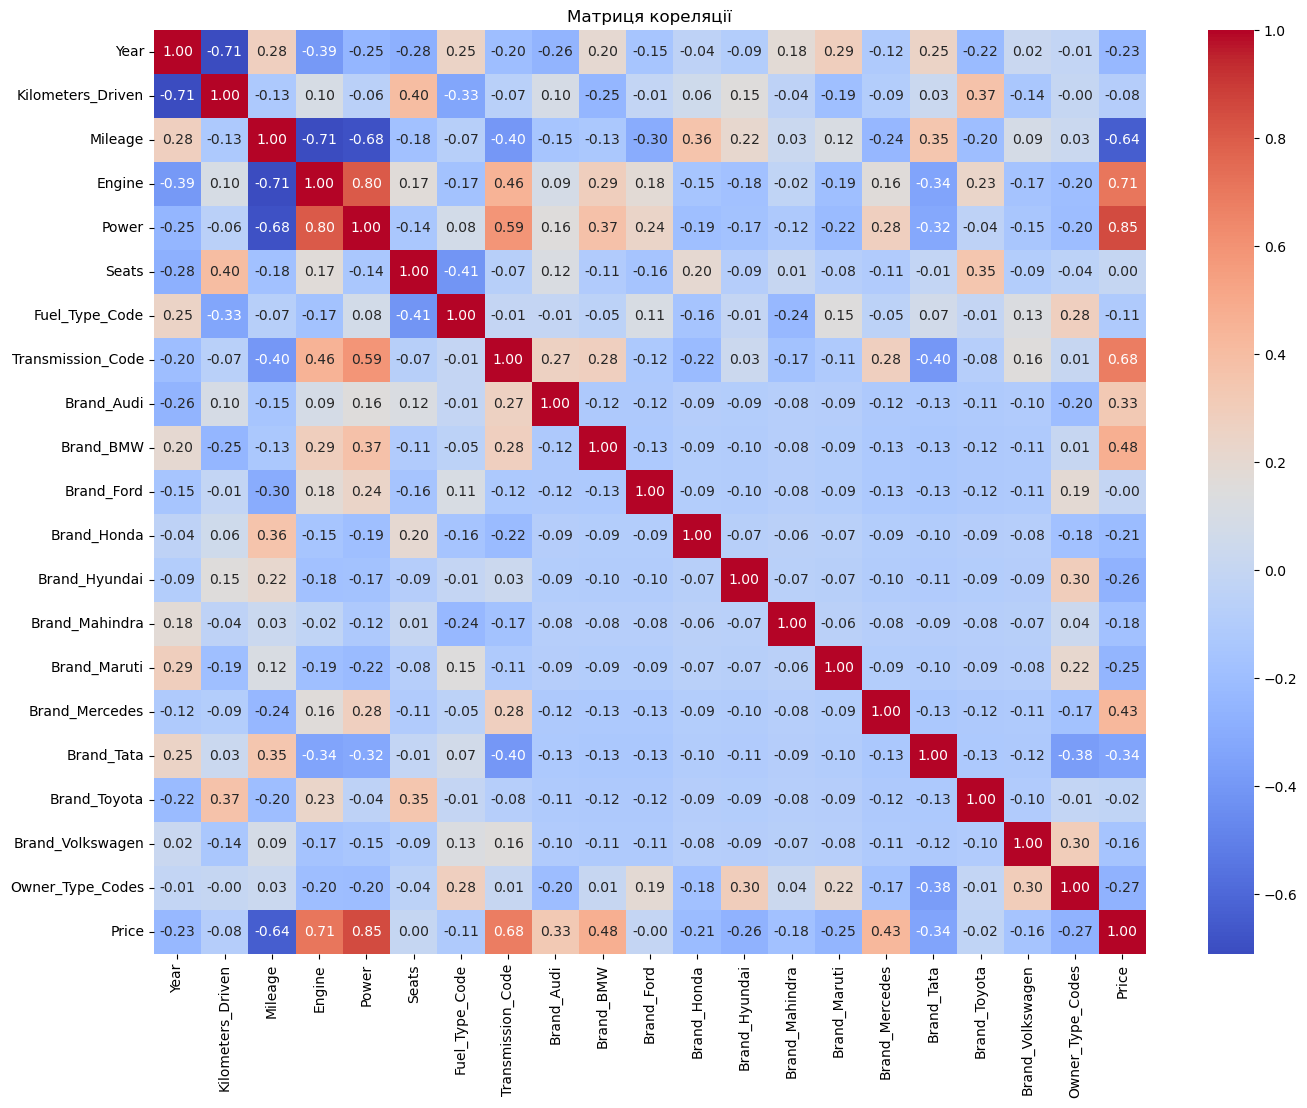

In [15]:
X_train_numeric = X_train.select_dtypes(include="number")

train_data = pd.concat([X_train_numeric, y_train], axis=1)

corr_matrix = train_data.corr()

plt.figure(figsize=(16, 12))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Матриця кореляції")
plt.show()

In [16]:
price_corr = corr_matrix["Price"].drop("Price")

strong_corr = price_corr[price_corr.abs() > 0.5]

print("Ознаки з кореляцією |r| > 0.5:")
print(strong_corr.sort_values(key=abs, ascending=False))

Ознаки з кореляцією |r| > 0.5:
Power                0.849137
Engine               0.710561
Transmission_Code    0.680731
Mileage             -0.638404
Name: Price, dtype: float64


Висновок: за результатами кореляційного аналізу виявлено 4 ознаки, які мають кореляцію з цільовою змінною `Price` понад 0.5 за модулем:

- `Power` (r = 0.849) — сильна позитивна кореляція: чим більша потужність автомобіля, тим вища його ціна.
- `Engine` (r = 0.711) — позитивна кореляція: автомобілі з більшим об'ємом двигуна зазвичай дорожчі.
- `Transmission_Code` (r = 0.681) — позитивна кореляція: автомобілі з автоматичною трансмісією зазвичай дорожчі.
- `Mileage` (r = -0.638) — негативна кореляція: автомобілі з більшою паливною ефективністю зазвичай мають нижчу ціну в цьому наборі даних.

Найсильніший зв'язок із ціною має ознака `Power` (r = 0.849).

**Завдання 6**. Тренуємо лінійну регресію.
0. Видаліть усі НЕчислові колонки з `X_train`, `X_test`, якщо ще цього не зробили.
1. Натренуйте лінійну регресую з `sklearn` на усіх числових даних тренувального набору `X_train`.
2. Зробіть передбачення на  `X_train`, `X_test`. Знайдіть і виведіть root mean squared error відхилення передбачення від справжніх значень цільової змінної.
3. Побудуйте графік розсіювання передбачень проти реальних даних цільової змінної для тренувального і тестувального наборів даних. Що можете сказати про якість моделі?

Train RMSE: 210342.80
Test RMSE: 259601.27


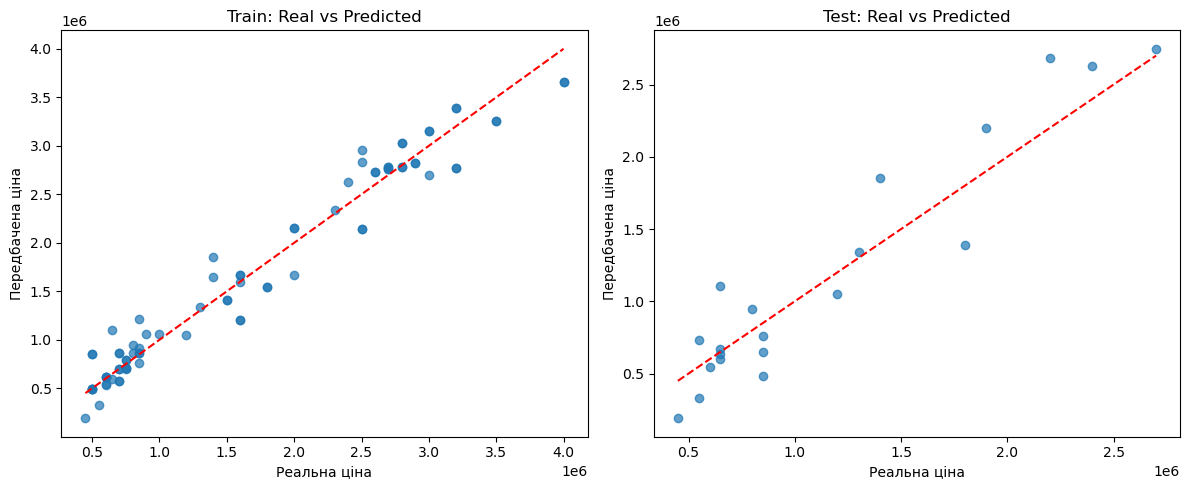

In [18]:
X_train_num = X_train.select_dtypes(include="number").drop(
    columns=["Car_ID"], errors="ignore"
)
X_test_num = X_test[X_train_num.columns]

model = LinearRegression()
model.fit(X_train_num, y_train)

y_train_pred = model.predict(X_train_num)
y_test_pred = model.predict(X_test_num)

train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))
test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))

print(f"Train RMSE: {train_rmse:.2f}")
print(f"Test RMSE: {test_rmse:.2f}")

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.scatter(y_train, y_train_pred, alpha=0.7)
plt.plot(
    [y_train.min(), y_train.max()],
    [y_train.min(), y_train.max()],
    "r--"
)
plt.xlabel("Реальна ціна")
plt.ylabel("Передбачена ціна")
plt.title("Train: Real vs Predicted")

plt.subplot(1, 2, 2)
plt.scatter(y_test, y_test_pred, alpha=0.7)
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--"
)
plt.xlabel("Реальна ціна")
plt.ylabel("Передбачена ціна")
plt.title("Test: Real vs Predicted")

plt.tight_layout()
plt.show()

Висновок: лінійна регресія показала досить хороші результати: Train RMSE = 210342.80 INR, Test RMSE = 259601.27 INR. На графіках більшість передбачень розташовані близько до лінії ідеального прогнозу, особливо на тренувальних даних. На тестових даних похибка дещо більша, проте модель загалом добре відображає залежність між характеристиками автомобілів та їхньою ціною. Є можливості для подальшого покращення точності моделі.

**Завдання 7**. Ми хочемо проаналізувати як впливає кожен чинник на цілову змінну. Для цього давайте промасштабуємо наші дані.
1. Зробіть масштабування незалежних змінних використовуючи `StandardScaler`. Тренуємо на тренувальних даних, а на тестувальних лише викликаємо `transform`.

2. Натренуйте модель на відмасштабованих даних і перегляньте коефіцієнти моделі. Які колонки є найвпливовішими на формування передбачення з точки зору коефіцієнтів? Проаналізуйте напрям дії найважливіших коефіцієнтів. Чи це логічно з точки зору значення відповідних змінних, що вони впливають на цільову змінну саме в напрямі збільшення / зменшення?

Коефіцієнти моделі:
Power                500000.506765
Brand_Mercedes       209257.737636
Brand_BMW            208105.079738
Brand_Audi           206123.092108
Fuel_Type_Code      -185245.840763
Brand_Hyundai       -151916.052473
Brand_Mahindra      -140931.632855
Mileage             -131884.633123
Brand_Ford          -119069.155830
Transmission_Code    115153.439599
Brand_Maruti        -112786.673613
Kilometers_Driven    -99713.958682
Brand_Volkswagen     -93391.358093
Brand_Tata           -65558.490423
Brand_Honda          -63112.339850
Owner_Type_Codes      43335.066079
Engine               -24683.084080
Brand_Toyota          17619.429555
Year                 -11604.260975
Seats                 -1744.048812
dtype: float64


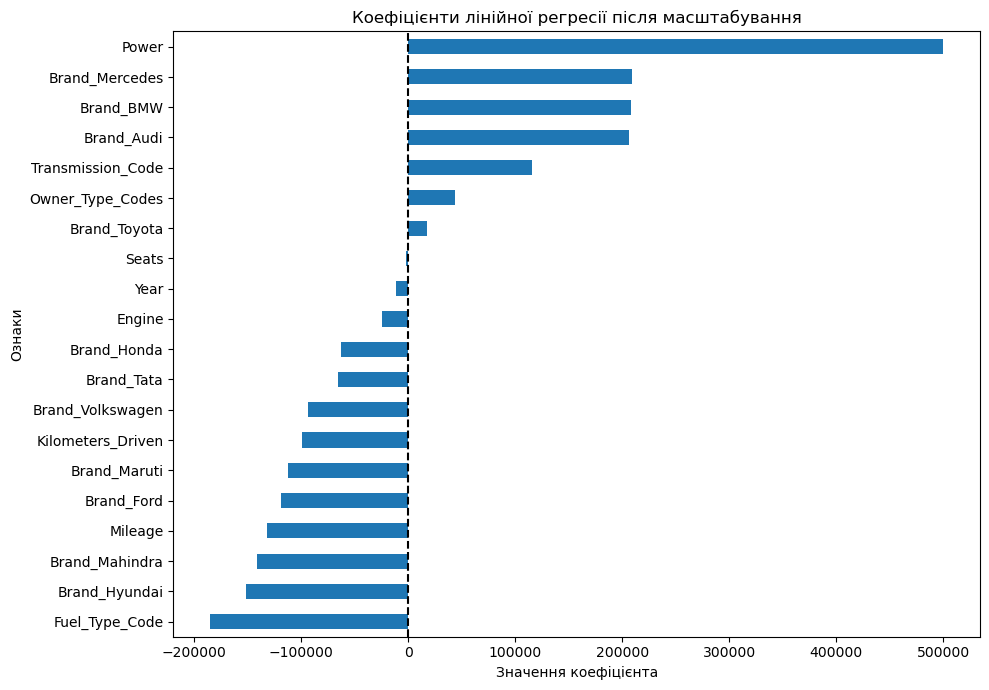

In [20]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_num)
X_test_scaled = scaler.transform(X_test_num)

model_scaled = LinearRegression()
model_scaled.fit(X_train_scaled, y_train)

coefficients = pd.Series(
    model_scaled.coef_,
    index=X_train_num.columns
)

coefficients = coefficients.reindex(
    coefficients.abs().sort_values(ascending=False).index
)

print("Коефіцієнти моделі:")
print(coefficients)

plt.figure(figsize=(10, 7))
coefficients.sort_values().plot(kind="barh")

plt.xlabel("Значення коефіцієнта")
plt.ylabel("Ознаки")
plt.title("Коефіцієнти лінійної регресії після масштабування")
plt.axvline(0, color="black", linestyle="--")
plt.tight_layout()
plt.show()

Висновок: найбільший позитивний вплив на прогнозовану ціну має `Power` (+500 001), а також бренди Mercedes, BMW та Audi. Найбільший негативний вплив мають `Fuel_Type_Code`, `Brand_Hyundai` та `Brand_Mahindra`. Загалом результати логічні: потужніші автомобілі преміальних брендів зазвичай дорожчі. Від'ємний коефіцієнт `Engine` може пояснюватися його взаємозв'язком з іншими ознаками.

**Завдання 8.** На тих самих відмасштабованих даних натренуйте модель з `statsmodels`. Виведіть звіт і проаналізуйте p-value коефіцієнтів. Які ознаки є стат значущими на рівні значущості 0.05? Напишіть їх список.

In [22]:
X_train_sm = pd.DataFrame(
    X_train_scaled,
    columns=X_train_num.columns,
    index=X_train_num.index
)

X_train_sm = sm.add_constant(X_train_sm)

model_sm = sm.OLS(y_train, X_train_sm).fit()

print(model_sm.summary())

significant = model_sm.pvalues.drop("const", errors="ignore")
significant = significant[significant < 0.05]

print("\nСтатистично значущі ознаки (p < 0.05):")
print(significant.sort_values())

                            OLS Regression Results                            
Dep. Variable:                  Price   R-squared:                       0.959
Model:                            OLS   Adj. R-squared:                  0.946
Method:                 Least Squares   F-statistic:                     73.14
Date:                Tue, 24 Nov 2026   Prob (F-statistic):           2.34e-34
Time:                        00:03:52   Log-Likelihood:                -1094.0
No. Observations:                  80   AIC:                             2228.
Df Residuals:                      60   BIC:                             2276.
Df Model:                          19                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
const               1.68e+06   2.72e+0

Висновок: на рівні значущості 0.05 статистично значущими виявилися 12 ознак: `Power`, `Mileage`, `Fuel_Type_Code`, `Transmission_Code`, `Brand_Audi`, `Brand_BMW`, `Brand_Ford`, `Brand_Hyundai`, `Brand_Mahindra`, `Brand_Maruti`, `Brand_Mercedes`, `Brand_Volkswagen`.

Усі ці ознаки мають p-value < 0.05, тому їхні коефіцієнти є статистично значущими.

**Завдання 9**. Натренуйте лінійну регресію з `statsmodels` тільки на ознаках, які виявлись стат. значущими в попередньому завданні. Проаналізуйте показники моделі. Чи значно змінились R2 і Adj. R-squared?

In [23]:
significant_features = significant.index.tolist()

X_train_significant = X_train_sm[significant_features]

X_train_significant = sm.add_constant(X_train_significant)

model_sm_significant = sm.OLS(
    y_train, X_train_significant
).fit()

print(model_sm_significant.summary())

print("Початкова модель:")
print(f"R²: {model_sm.rsquared:.4f}")
print(f"Adj. R²: {model_sm.rsquared_adj:.4f}")

print("\nМодель зі значущими ознаками:")
print(f"R²: {model_sm_significant.rsquared:.4f}")
print(f"Adj. R²: {model_sm_significant.rsquared_adj:.4f}")

                            OLS Regression Results                            
Dep. Variable:                  Price   R-squared:                       0.951
Model:                            OLS   Adj. R-squared:                  0.943
Method:                 Least Squares   F-statistic:                     109.4
Date:                Tue, 24 Nov 2026   Prob (F-statistic):           4.12e-39
Time:                        00:10:51   Log-Likelihood:                -1100.4
No. Observations:                  80   AIC:                             2227.
Df Residuals:                      67   BIC:                             2258.
Df Model:                          12                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
const               1.68e+06   2.78e+0

Висновок: після відбору статистично значущих ознак R² зменшився з 0.9586 до 0.9514, а Adj. R² - з 0.9455 до 0.9427. Зміни незначні, тому можна зробити висновок, що спрощена модель із 12 ознаками зберегла майже таку саму якість, як і початкова.

**Завдання 10**. Натренуйте лінійну регресію з `statsmodels` на усіх ознаках з масштабованого `X_train`, у яких p_value в завданні 8 менше за `0.25`. Ми таким чином помʼякшили критерій відбору ознак. Проаналізуйте показники моделі. Чи значно змінились R2 і Adj. R-squared порівняно з завданням 8? Яку модель з останніх 3х завдань ви б лишили для використання?

In [24]:
selected_features = model_sm.pvalues.drop(
    "const", errors="ignore"
)
selected_features = selected_features[
    selected_features < 0.25
].index.tolist()

print("Відібрані ознаки:", selected_features)

X_train_selected = X_train_sm[selected_features]
X_train_selected = sm.add_constant(X_train_selected)

model_sm_025 = sm.OLS(
    y_train, X_train_selected
).fit()

print(model_sm_025.summary())

comparison = pd.DataFrame({
    "Модель": [
        "Завдання 8 (усі ознаки)",
        "Завдання 9 (p < 0.05)",
        "Завдання 10 (p < 0.25)"
    ],
    "R²": [
        model_sm.rsquared,
        model_sm_significant.rsquared,
        model_sm_025.rsquared
    ],
    "Adj. R²": [
        model_sm.rsquared_adj,
        model_sm_significant.rsquared_adj,
        model_sm_025.rsquared_adj
    ]
})

display(comparison.round(4))

Відібрані ознаки: ['Kilometers_Driven', 'Mileage', 'Power', 'Fuel_Type_Code', 'Transmission_Code', 'Brand_Audi', 'Brand_BMW', 'Brand_Ford', 'Brand_Honda', 'Brand_Hyundai', 'Brand_Mahindra', 'Brand_Maruti', 'Brand_Mercedes', 'Brand_Tata', 'Brand_Volkswagen']
                            OLS Regression Results                            
Dep. Variable:                  Price   R-squared:                       0.958
Model:                            OLS   Adj. R-squared:                  0.948
Method:                 Least Squares   F-statistic:                     97.03
Date:                Tue, 24 Nov 2026   Prob (F-statistic):           4.85e-38
Time:                        00:14:52   Log-Likelihood:                -1094.7
No. Observations:                  80   AIC:                             2221.
Df Residuals:                      64   BIC:                             2260.
Df Model:                          15                                         
Covariance Type:            non

,Модель,R²,Adj. R²
0,Завдання 8 (усі ознаки),0.9586,0.9455
1,Завдання 9 (p < 0.05),0.9514,0.9427
2,Завдання 10 (p < 0.25),0.9579,0.9480


Висновок: після відбору ознак із p-value < 0.25 показник R² майже не змінився (0.9586 -> 0.9579), а Adj. R² навіть зріс (0.9455 -> 0.9480).

Я б обрала модель із завдання 10, оскільки вона використовує менше ознак, ніж початкова, зберігає майже таке саме R² та має найвище Adj. R² серед трьох моделей.